
Objetivo da Etapa 1. Agrupar os 26 circuitos do calendário em perfis estratégicos via
clusterização. O ID do cluster de cada circuito irá servir de feature-ponte para
a Etapa 2 (Subgroup Discovery em dados de piloto-corrida).

## Visão geral do pipeline

O fluxo, do dado bruto à partição final:

1. Coleta - telemetria de qualificação via FastF1, 26 circuitos.
2. Engenharia de features - derivação de 5 descritores dinâmicos por circuito + 3 features
   externas (abrasão, pit lane, altitude).
3. Poda por colinearidade - de 10 features telemétricas brutas para 5 representativas.
4. Definição de conjuntos candidatos — 5 feature sets, cada um com uma hipótese.
5. Clusterização - padronização + KMeans/Ward, k de 2 a 5.
6. Rubrica de decisão - filtros de viabilidade, estabilidade (bootstrap) e concordância
   entre algoritmos.
7. Robustez à inicialização - verificação de que o resultado do KMeans não é artefato de
   execução. 



## 1. Decisões de coleta de dados

Qualificação produz a "impressão digital" mais limpa do circuito: tanque leve, ataque máximo, sem a variabilidade estratégica de pit stops, gestão de pneu ou tráfego que contamina os tempos de corrida. 

A temporada de 2022 foi excluída integralment pois ouve falhas persistentes de API (`Failed to load session_info data!`). 

## 2. Engenharia das features

As 5 features dinâmicas por circuito:

`vel_media` velocidade média na volta (fluidez geral do traçado)

`vel_minima` velocidade mínima (percentil 1) (severidade da curva mais lenta)

`zonas_freio` nº de zonas de frenagem (densidade de eventos de frenagem)

`pico_desac` desaceleração de pico (dv/dt suavizado) (intensidade de frenagem longitudinal)

`densidade_curvas` nº de curvas / comprimento (km) (tortuosidade normalizada)

Decisões que vale destacar:

- `densidade_curvas` no lugar de `n_curvas`. Normalizei o número absoluto de curvas por km. 

- Agregação por percentil, não min/max. Para `vel_minima` e features de pico usei `nanpercentile(1)` e `nanpercentile(99)` em vez de mínimo/máximo absolutos. Telemetria de GPS tem sensibilidade a picos de ruído isolados.

Além das 5 dinâmicas, há 3 features externas/manuais: `abrasion` (cartão Pirelli), `pit_lane_time_loss_s` (site oficial/F1Technical) e `altitude_m`.

## 3. Carga e inspeção do dataset final

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score
)

RANDOM_STATE = 42

df = pd.read_csv("../data/processed/features_completas_por_circuito.csv")

TELEMETRIA = ["vel_media", "vel_minima", "zonas_freio", "pico_desac", "densidade_curvas"]
EXTERNAS   = ["abrasion", "pit_lane_time_loss_s", "altitude_m"]
TODAS      = TELEMETRIA + EXTERNAS

assert df.shape[0] == 26, f"Esperado 26 circuitos, encontrado {df.shape[0]}"
assert df[TODAS].isnull().sum().sum() == 0, "Há nulos nas features"

print(f"{df.shape[0]} circuitos, {len(TODAS)} features, sem nulos.\n")
df[["circuito"] + TODAS].describe().round(2)

26 circuitos, 8 features, sem nulos.



,vel_media,vel_minima,zonas_freio,pico_desac,densidade_curvas,abrasion,pit_lane_time_loss_s,altitude_m
count,26.00,26.00,26.00,26.00,26.00,26.00,26.00,26.00
mean,222.03,83.98,9.12,-31.12,3.33,2.71,22.09,240.08
std,19.66,14.44,1.77,2.98,0.78,0.95,3.00,467.67
min,165.04,49.99,7.00,-35.88,1.90,1.00,18.40,-25.00
25%,211.55,73.88,8.00,-33.07,2.81,2.00,19.90,10.50
50%,221.28,81.11,9.00,-31.66,3.25,3.00,20.90,47.00
75%,236.59,96.72,10.00,-29.78,3.65,3.00,23.67,228.25
max,258.07,109.04,13.00,-23.16,5.69,5.00,29.10,2232.00


## 4. Poda de features

A extração inicial gerou 10 descritores dinâmicos, muitos redundantes entre si. Uma matriz de correlação de Spearman entre os 10 mostrou blocos de alta colinearidade. Reduzi a 5 representantes não inflar artificialmente dimensões que medem a mesma coisa. 

As 3 externas têm correlação baixa com as features telemétricas, mas são ortogonais a telemetria. 

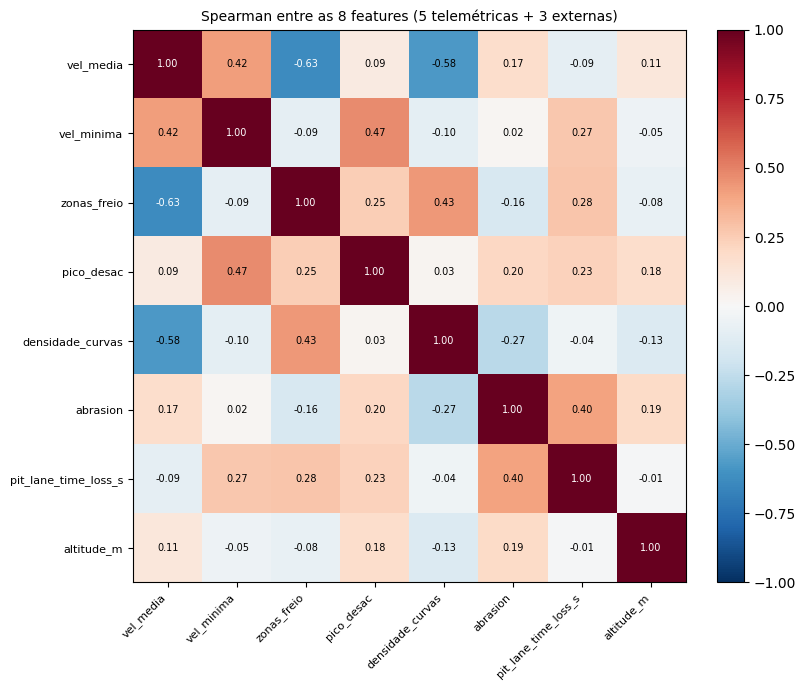

In [2]:
corr = df[TODAS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(TODAS))); ax.set_xticklabels(TODAS, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(TODAS))); ax.set_yticklabels(TODAS, fontsize=8)
for i in range(len(TODAS)):
    for j in range(len(TODAS)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i,j]) > 0.6 else "black")
plt.colorbar(im, fraction=0.046)
plt.title("Spearman entre as 8 features (5 telemétricas + 3 externas)", fontsize=10)
plt.tight_layout(); plt.show()


## 6. Conjuntos candidatos

Cinco feature sets, cada um testando uma hipótese.

In [3]:
feature_sets = {
    "todas": TODAS,  # vetor completo
    "so_dinamicas": TELEMETRIA,  # só telemetria 
    "so_dinamicas_sem_pico": ["vel_media", "vel_minima", "zonas_freio", "densidade_curvas"],
    "dinamicas_pit_altitude": TELEMETRIA + ["pit_lane_time_loss_s", "altitude_m"],
    "sem_pit_altitude": TELEMETRIA + ["abrasion"],
}

- Padronização (`StandardScaler`). 
- Algoritmos: KMeans, Ward (hierárquico, determinístico).
- k de 2 a 5. O teto de 5 evita a região onde, com 26 circuitos, qualquer partição vira grupos muito pequenos sem poder estatístico para a Etapa 2.
- Filtros de viabilidade: `min_cluster >= 2` (a fim de evitar clusters de 1 circuitos) e `k >= 3` (k=2 é a
  separação trivial Mônaco/Singapura vs. resto.

In [4]:
def fit_labels(X, k, algo, seed=RANDOM_STATE):
    if algo == "kmeans":
        return KMeans(n_clusters=k, random_state=seed, n_init=50).fit_predict(X)
    if algo == "ward":
        return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)

regs = []
for nome, feats in feature_sets.items():
    X = StandardScaler().fit_transform(df[feats])
    for k in range(2, 6):
        for algo in ["kmeans", "ward"]:
            lab = fit_labels(X, k, algo)
            sizes = sorted(Counter(lab).values())
            regs.append({"feature_set": nome, "k": k, "algo": algo,
                         "silhouette": silhouette_score(X, lab),
                         "davies_bouldin": davies_bouldin_score(X, lab),
                         "min_cluster": sizes[0], "n_real": len(sizes)})
grid = pd.DataFrame(regs)

viavel = grid[(grid["min_cluster"] >= 2) & (grid["k"] >= 3) & (grid["n_real"] == grid["k"])].copy()
print(f"Combinações testadas: {len(grid)} | viáveis após filtro: {len(viavel)}\n")
print("Top viáveis por silhouette:")
print(viavel.sort_values("silhouette", ascending=False).head(6).round(3).to_string(index=False))

Combinações testadas: 40 | viáveis após filtro: 22

Top viáveis por silhouette:
          feature_set  k   algo  silhouette  davies_bouldin  min_cluster  n_real
         so_dinamicas  4   ward       0.283           0.904            2       4
so_dinamicas_sem_pico  5 kmeans       0.277           0.879            2       5
so_dinamicas_sem_pico  5   ward       0.276           0.846            2       5
         so_dinamicas  3   ward       0.271           1.108            2       3
         so_dinamicas  3 kmeans       0.270           1.112            2       3
         so_dinamicas  5 kmeans       0.270           1.110            2       5


## 7. Estabilidade e concordância
- Estabilidade: remove ~15% dos circuitos aleatoriamente, reclusteriza, e mede a concordância (ARI) com a partição original.
- Concordância entre algoritmos: ARI entre KMeans e Ward na mesma `(feature_set, k)`.

In [5]:
def estabilidade(feats, k, algo, n_iter=200, frac=0.85, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    Xf = StandardScaler().fit_transform(df[feats])
    base = fit_labels(Xf, k, algo, seed=seed)
    n_sub = int(len(df) * frac)
    aris = []
    for _ in range(n_iter):
        idx = rng.choice(len(df), size=n_sub, replace=False)
        sub = fit_labels(Xf[idx], k, algo, seed=int(rng.integers(1_000_000)))
        aris.append(adjusted_rand_score(base[idx], sub))
    return float(np.mean(aris))

def concord_kmeans_ward(feats, k):
    X = StandardScaler().fit_transform(df[feats])
    return adjusted_rand_score(fit_labels(X, k, "kmeans"), fit_labels(X, k, "ward"))

linhas = []
for _, r in viavel.iterrows():
    feats = feature_sets[r["feature_set"]]
    linhas.append({**r.to_dict(),
                   "ari_mean": estabilidade(feats, int(r["k"]), r["algo"]),
                   "kmeans_vs_ward": concord_kmeans_ward(feats, int(r["k"]))})
painel = pd.DataFrame(linhas)

aprovados = painel[(painel["ari_mean"] >= 0.6) & (painel["kmeans_vs_ward"] >= 0.6)].copy()
print(f"Aprovados (estabilidade + concordância): {len(aprovados)}\n")
print(aprovados.sort_values("silhouette", ascending=False)[
    ["feature_set", "k", "algo", "silhouette", "davies_bouldin", "ari_mean", "kmeans_vs_ward"]
].round(3).to_string(index=False))

Aprovados (estabilidade + concordância): 12

           feature_set  k   algo  silhouette  davies_bouldin  ari_mean  kmeans_vs_ward
          so_dinamicas  4   ward       0.283           0.904     0.857           0.731
 so_dinamicas_sem_pico  5 kmeans       0.277           0.879     0.826           0.717
 so_dinamicas_sem_pico  5   ward       0.276           0.846     0.735           0.717
          so_dinamicas  3   ward       0.271           1.108     0.888           0.854
          so_dinamicas  3 kmeans       0.270           1.112     0.861           0.854
          so_dinamicas  5 kmeans       0.270           1.110     0.744           0.912
          so_dinamicas  4 kmeans       0.270           1.000     0.818           0.731
          so_dinamicas  5   ward       0.270           1.097     0.805           0.912
      sem_pit_altitude  4 kmeans       0.215           1.179     0.668           0.719
      sem_pit_altitude  3 kmeans       0.210           1.349     0.664           0.72

- Como são poucos circuitos e eles não formam categorias naturais muito nítidas não considerei apenas silhouette, mas também estabilidade, concordância entre algoritmos e interpretabilidade dos grupos. Com k = 4, a solução do KMeans ficou estável quando rodei múltiplas inicializações, não gerou uma fragmentação excessiva da amostra e produziu grupos que fazem sentido no domínio

In [11]:
print("Aprovados (passam estabilidade + concordância):")
print(aprovados.sort_values("silhouette", ascending=False).round(3).to_string(index=False))

print("\nTop por silhueta entre viáveis:")
print(viavel.sort_values("silhouette", ascending=False).head(8).round(3).to_string(index=False))

Aprovados (passam estabilidade + concordância):
           feature_set  k   algo  silhouette  davies_bouldin  min_cluster  n_real  ari_mean  kmeans_vs_ward
          so_dinamicas  4   ward       0.283           0.904            2       4     0.857           0.731
 so_dinamicas_sem_pico  5 kmeans       0.277           0.879            2       5     0.826           0.717
 so_dinamicas_sem_pico  5   ward       0.276           0.846            2       5     0.735           0.717
          so_dinamicas  3   ward       0.271           1.108            2       3     0.888           0.854
          so_dinamicas  3 kmeans       0.270           1.112            2       3     0.861           0.854
          so_dinamicas  5 kmeans       0.270           1.110            2       5     0.744           0.912
          so_dinamicas  4 kmeans       0.270           1.000            2       4     0.818           0.731
          so_dinamicas  5   ward       0.270           1.097            2       5     0.

Três candidatos passam em tudo, e os dois melhores são ambos `so_dinamicas, k=4`(Ward e KMeans). Os conjuntos com features externas ficam para trás justamente pela razão da Seção 4 (dilui a coesão). 

## 8. Robustez do KMeans à inicialização 

Investiga se KMeans não seria um artefato de execução, e como seria a variância ao rodá-lo múltiplas vezes. Rodei o KMeans em 200 seeds, em dois cenários: `n_init=50` (o que de fato uso) e `n_init=1` (pior caso, single shot).

In [7]:
ALGO_ESCOLHIDO = "kmeans"  

FEATS = feature_sets["so_dinamicas"]
K = 4  

linha = candidatos_k4[
    (candidatos_k4["feature_set"] == "so_dinamicas") &
    (candidatos_k4["algo"] == ALGO_ESCOLHIDO)
]
assert len(linha) == 1, f"Candidato so_dinamicas/{ALGO_ESCOLHIDO}/k={K} não encontrado em candidatos_k4"

print(f"(silhouette={linha['silhouette'].values[0]:.3f})")

X = StandardScaler().fit_transform(df[FEATS])
N_SEEDS = 200

def coleta(X, k, n_seeds, n_init):
    regs, labs = [], []
    for s in range(n_seeds):
        l = KMeans(n_clusters=k, random_state=s, n_init=n_init).fit_predict(X)
        regs.append({"silhouette": silhouette_score(X, l),
                     "davies_bouldin": davies_bouldin_score(X, l),
                     "calinski_harabasz": calinski_harabasz_score(X, l)})
        labs.append(l)
    return pd.DataFrame(regs), labs

v50, lab50 = coleta(X, K, N_SEEDS, 50)
v1,  lab1  = coleta(X, K, N_SEEDS, 1)
lw = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
ward = {m: f(X, lw) for m, f in [("silhouette", silhouette_score),
        ("davies_bouldin", davies_bouldin_score), ("calinski_harabasz", calinski_harabasz_score)]}

print(f"\n=== KMeans em {N_SEEDS} seeds (so_dinamicas, k={K}) ===\n")
for m in ["silhouette", "davies_bouldin", "calinski_harabasz"]:
    print(f"{m}:")
    print(f"  n_init=50: média={v50[m].mean():.4f} dp={v50[m].std():.4f} [{v50[m].min():.4f}, {v50[m].max():.4f}]")
    print(f"  n_init=1:  média={v1[m].mean():.4f} dp={v1[m].std():.4f} [{v1[m].min():.4f}, {v1[m].max():.4f}]")
    print(f"  Ward:      {ward[m]:.4f}\n")

(silhouette=0.270)

=== KMeans em 200 seeds (so_dinamicas, k=4) ===

silhouette:
  n_init=50: média=0.2698 dp=0.0000 [0.2698, 0.2698]
  n_init=1:  média=0.2195 dp=0.0386 [0.0957, 0.2830]
  Ward:      0.2829

davies_bouldin:
  n_init=50: média=1.0001 dp=0.0000 [1.0001, 1.0001]
  n_init=1:  média=1.1152 dp=0.1587 [0.9124, 1.6146]
  Ward:      0.9036

calinski_harabasz:
  n_init=50: média=12.8560 dp=0.0000 [12.8560, 12.8560]
  n_init=1:  média=10.7042 dp=1.6322 [6.8567, 12.8560]
  Ward:      12.0430



In [8]:
def canonica(l):
    mapa, out, p = {}, [], 0
    for x in l:
        if x not in mapa: mapa[x] = p; p += 1
        out.append(mapa[x])
    return tuple(out)

c50, c1 = Counter(map(canonica, lab50)), Counter(map(canonica, lab1))
print("Partições estruturalmente distintas em 200 seeds:")
print(f"  n_init=50: {len(c50)} única(s), modal em {max(c50.values())}/{N_SEEDS}")
print(f"  n_init=1:  {len(c1)} distintas, modal em {max(c1.values())}/{N_SEEDS}")

rng = np.random.default_rng(RANDOM_STATE)
def ari_pares(labs, n=500):
    pr = rng.choice(len(labs), size=(n, 2)); pr = pr[pr[:,0] != pr[:,1]]
    return np.mean([adjusted_rand_score(labs[i], labs[j]) for i, j in pr])
print(f"\nARI médio entre pares: n_init=50={ari_pares(lab50):.3f} | n_init=1={ari_pares(lab1):.3f}")

final = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=50).fit_predict(X)
modal50 = c50.most_common(1)[0][0]
print(f"\nPartição reportada (seed 42) é a modal sob n_init=50? "
      f"{'Sim' if canonica(final) == modal50 else 'Não'}")

Partições estruturalmente distintas em 200 seeds:
  n_init=50: 1 única(s), modal em 200/200
  n_init=1:  112 distintas, modal em 20/200

ARI médio entre pares: n_init=50=1.000 | n_init=1=0.462

Partição reportada (seed 42) é a modal sob n_init=50? Sim


Pares com coassociação >= 0.8 (65 pares):

  Austin                              <-> Mexico City                          1.00
  Austin                              <-> Miami                                1.00
  Austin                              <-> Montréal                             1.00
  Austin                              <-> Sakhir                               1.00
  Austin                              <-> Shanghai                             1.00
  Austin                              <-> Yas Island                           1.00
  Barcelona                           <-> Imola                                1.00
  Barcelona                           <-> Jeddah                               1.00
  Barcelona                           <-> Las Vegas                            1.00
  Barcelona                           <-> Lusail                               1.00
  Barcelona                           <-> Melbourne                            1.00
  Barcelona                      

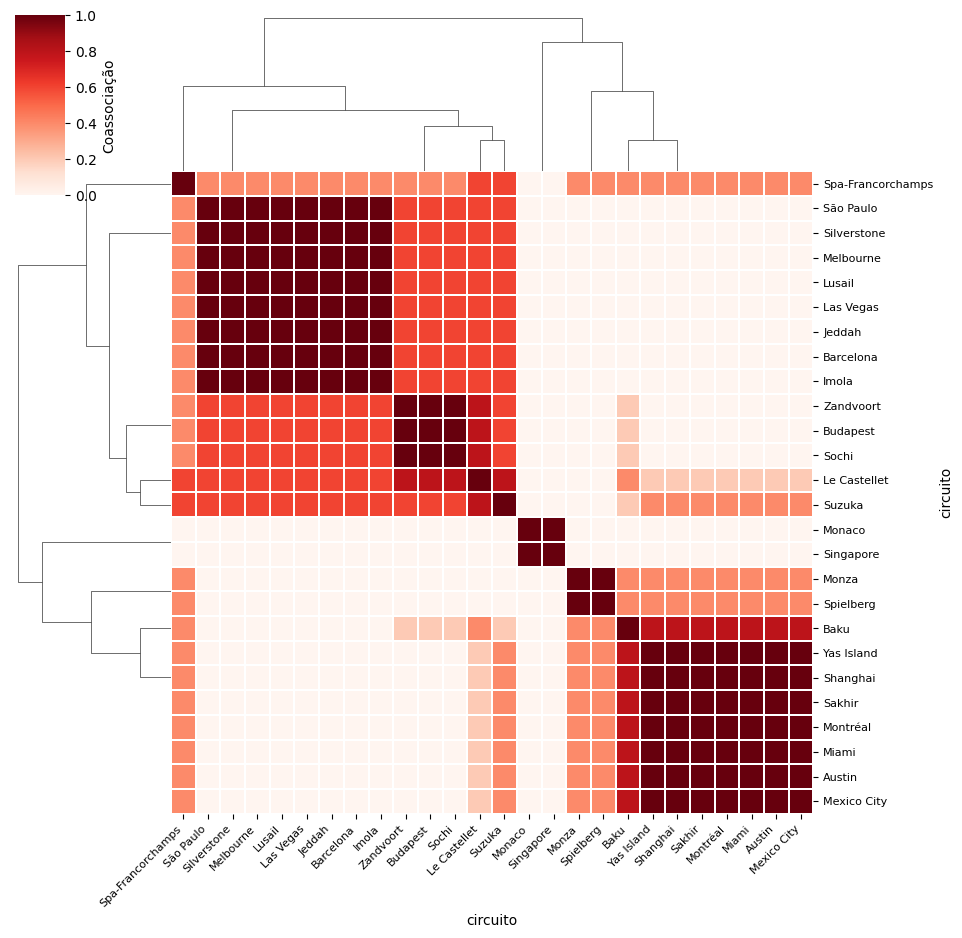

In [10]:
# ===========================================================
# Matriz de coassociação sobre o top-5 de partições aprovadas
# Detecta núcleos de circuitos que permanecem juntos
# independentemente da escolha final de k/algoritmo/features.
# ===========================================================
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Top-5 configurações (entre as aprovadas pela rubrica) ---
TOP5 = [
    ("so_dinamicas",          4, "ward"),
    ("so_dinamicas_sem_pico", 5, "kmeans"),
    ("so_dinamicas_sem_pico", 5, "ward"),
    ("so_dinamicas",          3, "ward"),
    ("so_dinamicas",          3, "kmeans"),
]

# --- 2. Refit em cada configuração, empilhando os rótulos ---
labels_dict = {}
for fs, k, algo in TOP5:
    X = StandardScaler().fit_transform(df[feature_sets[fs]])
    labels_dict[f"{fs}__k{k}__{algo}"] = fit_labels(X, k, algo)

labels_df = pd.DataFrame(labels_dict, index=df["circuito"])

# --- 3. Coassociação ---
def matriz_coassociacao(labels_df: pd.DataFrame) -> pd.DataFrame:
    """
    Para cada par (i, j) de circuitos, retorna a fração das partições
    candidatas em que i e j caem no mesmo cluster.
    Invariante à permutação de rótulos -> compara k diferentes entre si.
    """
    L = labels_df.values
    n_circ, n_part = L.shape
    M = np.zeros((n_circ, n_circ), dtype=float)
    for p in range(n_part):
        col = L[:, p]
        M += (col[:, None] == col[None, :]).astype(float)
    return pd.DataFrame(M / n_part, index=labels_df.index, columns=labels_df.index)

C = matriz_coassociacao(labels_df)

# --- 4. Pares com alta coassociação (potenciais núcleos persistentes) ---
LIMIAR = 0.80
n = C.shape[0]
nomes = C.index.tolist()
pares = [
    (nomes[i], nomes[j], C.iat[i, j])
    for i in range(n) for j in range(i + 1, n)
    if C.iat[i, j] >= LIMIAR
]
pares.sort(key=lambda x: -x[2])

print(f"Pares com coassociação >= {LIMIAR} ({len(pares)} pares):\n")
for a, b, v in pares:
    print(f"  {a:35s} <-> {b:35s}  {v:.2f}")

# --- 5. Heatmap reordenado por clusterização hierárquica da própria matriz ---
g = sns.clustermap(
    C, cmap="Reds", figsize=(10, 10),
    vmin=0, vmax=1, linewidths=0.3, linecolor="white",
    cbar_kws={"label": "Coassociação"},
)
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right", fontsize=8)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), rotation=0, fontsize=8)
plt.show()

## 9. Clusters Ward vs KMeans 

Composição dos clusters.

In [ ]:
def composicao(labels, titulo):
    tmp = df.copy(); tmp["cluster"] = labels
    print(f"\n=== {titulo} ===")
    for c in sorted(tmp["cluster"].unique()):
        circs = sorted(tmp.loc[tmp["cluster"]==c, "circuito"].tolist())
        print(f"  Cluster {c} (n={len(circs)}): {circs}")
    print(tmp.groupby("cluster")[FEATS].mean().round(2))

composicao(lw,    "WARD (silhouette 0.283)")
composicao(final, "KMEANS (silhouette 0.270)")
print(f"\nARI entre as duas partições: {adjusted_rand_score(lw, final):.3f}")


=== WARD (silhouette 0.283) ===
  Cluster 0 (n=14): ['Barcelona', 'Budapest', 'Imola', 'Jeddah', 'Las Vegas', 'Le Castellet', 'Lusail', 'Melbourne', 'Silverstone', 'Sochi', 'Spa-Francorchamps', 'Suzuka', 'São Paulo', 'Zandvoort']
  Cluster 1 (n=2): ['Monaco', 'Singapore']
  Cluster 2 (n=8): ['Austin', 'Baku', 'Mexico City', 'Miami', 'Montréal', 'Sakhir', 'Shanghai', 'Yas Island']
  Cluster 3 (n=2): ['Monza', 'Spielberg']
         vel_media  vel_minima  zonas_freio  pico_desac  densidade_curvas
cluster                                                                  
0           229.92       94.26         8.86      -29.25              3.21
1           178.09       61.14        13.00      -30.95              5.18
2           212.55       73.92         9.12      -33.45              3.39
3           248.63       75.02         7.00      -35.07              2.11

=== KMEANS (silhouette 0.270) ===
  Cluster 0 (n=11): ['Barcelona', 'Budapest', 'Imola', 'Jeddah', 'Le Castellet', 'Lusail', 'Sil

Divergência: Power Circuits de baixo downforce (Monza, Spa, Las Vegas, Melbourne, Spielberg):

- Ward os coloca num cluster grande e heterogêneo (14 circuitos), junto a traçados de alto downforce e tecnicamente exigentes (Silverstone, Imola, Suzuka).
- KMeans os isola num grupo próprio (n=5), com perfil coerente: maior `vel_media`, menos zonas de frenagem, menor densidade de curvas.